# Tier 2: Article Credibility Assessment (v2)

The final Tier 2 system: five PubMedBERT models with an ordinal rating head and ten criteria heads, evaluated on the 318 test articles. It runs through `tier2/engine.py`, the same code the web app uses.

In [1]:
import json, os, sys, time, inspect, itertools, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score)
from transformers import AutoModelForSequenceClassification, AutoTokenizer

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "experiments_tier2"))
from tier2.engine import (CRITERIA, CRITERION_NAME, DISPLAY, MODEL_DIR, Tier2Engine, article_text)
from tier2 import explanation_checks as FA
from pipeline import ROUTER_MAX_WORDS, route

DATA, OUTP, FIG = ROOT / "datasets" / "processed_tier2", ROOT / "outputs", ROOT / "outputs" / "figures"
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

# figures: black and white only, recessive axes
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#888",
                     "axes.labelcolor": "#222", "xtick.color": "#555", "ytick.color": "#555"})

train, val, test = (pd.read_csv(DATA / f"{s}.csv") for s in ("train", "validation", "test"))
LABELS = ["NOT_CREDIBLE", "CREDIBLE"]
y_val = (val.binary_label == "CREDIBLE").astype(int).values
y_test = (test.binary_label == "CREDIBLE").astype(int).values
BASE_RATE = float((train.binary_label == "NOT_CREDIBLE").mean())
X = {n: [article_text(a, b) for a, b in zip(d.title, d.text)]
     for n, d in (("train", train), ("val", val), ("test", test))}
Y_CRIT = {n: d[[f"fail_{k}" for k in CRITERIA]].values.astype(float)
          for n, d in (("train", train), ("val", val), ("test", test))}
print(f"train {len(train)}  validation {len(val)}  test {len(test)}   "
      f"NOT_CREDIBLE rate in training: {BASE_RATE:.3f}")
print("device:", ("cuda - " + torch.cuda.get_device_name(0)) if torch.cuda.is_available() else "cpu")

train 1483  validation 318  test 318   NOT_CREDIBLE rate in training: 0.335
device: cuda - NVIDIA GeForce RTX 5050 Laptop GPU


## 1. Data

FakeHealth, split 1,483 / 318 / 318. A rating of 2 stars or fewer is `NOT_CREDIBLE`.

In [2]:
d = pd.concat([train, val, test], ignore_index=True)
print("Articles per source and label")
print(pd.crosstab(d.subset, d.binary_label, margins=True), "\n")
print("Star rating (0-5) against the binary label")
print(pd.crosstab(d.rating, d.binary_label), "\n")
assert ((d.rating <= 2) == (d.binary_label == "NOT_CREDIBLE")).all()
print("check passed: NOT_CREDIBLE is exactly rating <= 2\n")
words = pd.Series([len(t.split()) for t in X["train"] + X["val"] + X["test"]])
print("Words per article (title + text):", words.describe()[["min", "25%", "50%", "75%", "max"]].round(0).to_dict())

Articles per source and label
binary_label   CREDIBLE  NOT_CREDIBLE   All
subset                                     
HealthRelease       308           285   593
HealthStory        1101           425  1526
All                1409           710  2119 

Star rating (0-5) against the binary label
binary_label  CREDIBLE  NOT_CREDIBLE
rating                              
0                    0            29
1                    0           180
2                    0           501
3                  688             0
4                  494             0
5                  227             0 

check passed: NOT_CREDIBLE is exactly rating <= 2

Words per article (title + text): {'min': 64.0, '25%': 452.0, '50%': 644.0, '75%': 842.0, 'max': 4296.0}


In [3]:
rows = []
for j, k in enumerate(CRITERIA):
    col = train[f"fail_{k}"]
    rows.append({"criterion": k, "question": CRITERION_NAME[k], "graded": int(col.notna().sum()),
                 "fail rate": round(float(col.mean()), 3)})
print("Training set: how often each criterion is graded, and how often it is failed")
print(pd.DataFrame(rows).to_string(index=False))
frac_failed = d[[f"fail_{k}" for k in CRITERIA]].mean(axis=1)
print(f"\ncorrelation(star rating, fraction of graded criteria failed) = {d.rating.corr(frac_failed):.3f}")
print(f"criteria graded per article: {d[[f'fail_{k}' for k in CRITERIA]].notna().sum(1).mean():.1f}")

Training set: how often each criterion is graded, and how often it is failed
        criterion                                               question  graded  fail rate
            costs                                        Discusses costs    1236      0.752
         benefits                                Quantifies the benefits    1472      0.666
            harms                                   Quantifies the harms    1367      0.666
 evidence_quality                   Explains the quality of the evidence    1481      0.635
disease_mongering                               Avoids disease-mongering    1426      0.135
 independent_srcs             Independent sources, conflicts of interest    1062      0.487
     alternatives                    Compares with existing alternatives    1409      0.507
     availability                               Establishes availability    1283      0.278
          novelty                               Establishes true novelty    1433      0.304
   

## 2. Model

One PubMedBERT encoder (first 512 tokens) with a CORAL ordinal head and ten masked criteria heads, trained with five seeds. There is no binary head.

In [4]:
import model_and_variant_sweep
print(inspect.getsource(model_and_variant_sweep.T2Model))

class T2Model(nn.Module):
    """Shared encoder, up to three heads.

    ordinal head is CORAL: one shared direction w plus K-1 ordered biases, so the
    cumulative probabilities P(rating>k) are monotone in k by construction and the
    five tasks cannot contradict each other.
    """

    def __init__(self, backbone, heads, class_w=None, crit_pw=None, ord_pw=None,
                 w_bin=1.0, w_crit=0.5, w_ord=0.5, grad_ckpt=False):
        super().__init__()
        # transformers 5.x loads weights in the checkpoint's own dtype. deberta-v3-base
        # ships as fp16, which ran the encoder in pure fp16 (-> NaN logits) while the
        # heads stayed fp32 (-> "Half != float"). Always materialise in fp32 and let
        # autocast handle mixed precision.
        self.enc = AutoModel.from_pretrained(backbone, dtype=torch.float32)
        if grad_ckpt:
            self.enc.gradient_checkpointing_enable()
        h = self.enc.config.hidden_size
        self.heads = set(heads)
        se

In [5]:
meta = json.load(open(MODEL_DIR / "meta.json"))
print(f"backbone {meta['backbone']}\nheads {meta['heads']}   epochs {meta['epochs']}   max_len {meta['max_len']}")
print(f"seeds {meta['seeds']}   built {meta['built']}\n")
print("Per-epoch log (validation macro-F1 of the ordinal head at 0.5; '<- best' marks the kept checkpoint)")
for sd, h in meta["history"].items():
    print(f"  seed {sd}  ({h['minutes']} min)")
    for line in h["epochs"]:
        print("     ", line)

backbone microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext
heads ['criteria', 'ordinal']   epochs 5   max_len 512
seeds [42, 1337, 2024, 7, 99]   built 2026-09-27 11:46:53

Per-epoch log (validation macro-F1 of the ordinal head at 0.5; '<- best' marks the kept checkpoint)
  seed 42  (3.77 min)
      ep1 loss=0.6449 val_macroF1(ord)=0.5971  <- best
      ep2 loss=0.5972 val_macroF1(ord)=0.6322  <- best
      ep3 loss=0.5283 val_macroF1(ord)=0.5859
      ep4 loss=0.4740 val_macroF1(ord)=0.5619
      ep5 loss=0.4398 val_macroF1(ord)=0.5249
  seed 1337  (3.75 min)
      ep1 loss=0.6501 val_macroF1(ord)=0.5178  <- best
      ep2 loss=0.6010 val_macroF1(ord)=0.5685  <- best
      ep3 loss=0.5430 val_macroF1(ord)=0.5075
      ep4 loss=0.4932 val_macroF1(ord)=0.4272
      ep5 loss=0.4565 val_macroF1(ord)=0.4628
  seed 2024  (3.65 min)
      ep1 loss=0.6455 val_macroF1(ord)=0.4660  <- best
      ep2 loss=0.6022 val_macroF1(ord)=0.5796  <- best
      ep3 loss=0.5491 val_macroF1(ord)=

## 3. Loading the saved system

In [6]:
t0 = time.time()
eng = Tier2Engine()
print(f"loaded {len(eng.members)} ensemble members + criteria hybrid on {eng.device} in {time.time()-t0:.1f}s")

t0 = time.time(); S_val = eng.score(X["val"]); S_test = eng.score(X["test"])
secs = (time.time() - t0) / (len(X["val"]) + len(X["test"]))
print(f"scored {len(X['val'])+len(X['test'])} articles, {secs*1000:.0f} ms per article")

saved = np.load(OUTP / "tier2_preds" / "ENSV2__crit_lr__sENS__test.npy")
print(f"max |engine - training script|, verdict score:   {np.abs(S_test['credibility'] - saved).max():.1e}")
saved = np.load(OUTP / "tier2_preds" / "HYB__criteria__test.npy")
same = all(np.isclose(roc_auc_score(Y_CRIT['test'][m, j], S_test['criteria'][m, j]),
                      roc_auc_score(Y_CRIT['test'][m, j], saved[m, j]))
           for j in range(10) for m in [~np.isnan(Y_CRIT['test'][:, j])])
print(f"criteria: engine ranks every criterion exactly as the hybrid script did: {same}")

loaded 5 ensemble members + criteria hybrid on cuda in 5.0s


scored 636 articles, 30 ms per article
max |engine - training script|, verdict score:   9.5e-08
criteria: engine ranks every criterion exactly as the hybrid script did: True


## 4. The verdict

The threshold is set on validation so the model flags the same share of articles as the training data (rate matching).

In [7]:
THR = eng.threshold
pred_v2 = (S_test["credibility"] >= THR).astype(int)

def metrics(y, pred, score):
    rec = ((pred == 0) & (y == 0)).sum() / max((y == 0).sum(), 1)
    return {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
            "recall_not_credible": rec, "roc_auc": roc_auc_score(y, score),
            "predicted_not_credible": float((pred == 0).mean())}

m_v2 = metrics(y_test, pred_v2, S_test["credibility"])
print(f"verdict threshold {THR:.4f} (validation quantile at the training base rate {BASE_RATE:.3f})\n")
for k, v in m_v2.items():
    print(f"  {k:<24}{v:.4f}")
print(f"  {'true not-credible rate':<24}{(y_test == 0).mean():.4f}\n")
print(classification_report(y_test, pred_v2, target_names=LABELS, digits=3))

verdict threshold 0.4719 (validation quantile at the training base rate 0.335)

  accuracy                0.7327
  macro_f1                0.6971
  recall_not_credible     0.5794
  roc_auc                 0.7256
  predicted_not_credible  0.3208
  true not-credible rate  0.3365

              precision    recall  f1-score   support

NOT_CREDIBLE      0.608     0.579     0.593       107
    CREDIBLE      0.792     0.810     0.801       211

    accuracy                          0.733       318
   macro avg      0.700     0.695     0.697       318
weighted avg      0.730     0.733     0.731       318



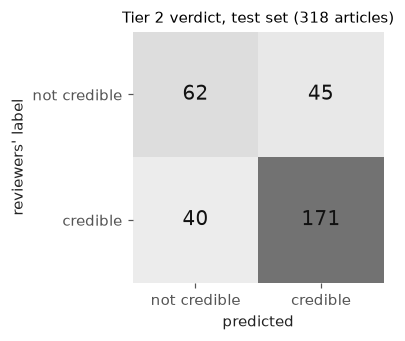

In [8]:
cm = confusion_matrix(y_test, pred_v2)
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.6)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="#111")
ax.set_xticks([0, 1], ["not credible", "credible"]); ax.set_yticks([0, 1], ["not credible", "credible"])
ax.set_xlabel("predicted"); ax.set_ylabel("reviewers' label")
ax.set_title("Tier 2 verdict, test set (318 articles)", fontsize=10)
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "tier2_v2_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

### Against every baseline, on the same 318 articles

In [9]:
@torch.no_grad()
def score_hf(model_dir, texts, multilabel=False, bs=16):
    tok = AutoTokenizer.from_pretrained(model_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_dir).to(eng.device).eval()
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], truncation=True, max_length=512, padding=True, return_tensors="pt").to(eng.device)
        lg = mdl(**enc).logits.float()
        out.append((torch.sigmoid(lg) if multilabel else torch.softmax(lg, -1)[:, 1]).cpu().numpy())
    del mdl
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return np.concatenate(out)

# v1 and BERT-base, re-scored live with their shipped rule (argmax)
s_v1 = score_hf(ROOT / "models" / "tier2_final", X["test"])
s_bb = score_hf(ROOT / "models" / "tier2_bertbase_binary", X["test"])
pred_v1, pred_bb = (s_v1 >= 0.5).astype(int), (s_bb >= 0.5).astype(int)

# TF-IDF + logistic regression: "canonical" is the configuration used in the dataset
# investigation; "tuned" is the best of 24 configurations on VALIDATION.
def tfidf_run(mf, ng, sub, sw):
    v = TfidfVectorizer(max_features=mf, ngram_range=ng, sublinear_tf=sub, stop_words=sw, min_df=2)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(
        v.fit_transform(X["train"]), (train.binary_label == "CREDIBLE").astype(int))
    sv, st = clf.predict_proba(v.transform(X["val"]))[:, 1], clf.predict_proba(v.transform(X["test"]))[:, 1]
    return sv, st, np.quantile(sv, BASE_RATE)

tf_runs = {}
for cfg in itertools.product([20000, 50000, None], [(1, 1), (1, 2)], [True, False], ["english", None]):
    sv, st, thr = tfidf_run(*cfg)
    tf_runs[cfg] = {"val_f1": f1_score(y_val, (sv >= thr).astype(int), average="macro"), "st": st, "thr": thr}
canon = (50000, (1, 2), True, None)
tuned = max(tf_runs, key=lambda c: tf_runs[c]["val_f1"])
pred_tf_c = (tf_runs[canon]["st"] >= tf_runs[canon]["thr"]).astype(int)
pred_tf_t = (tf_runs[tuned]["st"] >= tf_runs[tuned]["thr"]).astype(int)
test_f1s = [f1_score(y_test, (r["st"] >= r["thr"]).astype(int), average="macro") for r in tf_runs.values()]
print(f"TF-IDF configuration chosen on validation: max_features={tuned[0]}, ngrams={tuned[1]}, "
      f"sublinear={tuned[2]}, stop_words={tuned[3]}")
print(f"TF-IDF test macro-F1 across all 24 configurations: {min(test_f1s):.3f} to {max(test_f1s):.3f}\n")

table = pd.DataFrame({
    "v2 ensemble (shipped)": m_v2,
    "v1 PubMedBERT binary": metrics(y_test, pred_v1, s_v1),
    "BERT-base binary": metrics(y_test, pred_bb, s_bb),
    "TF-IDF + LR, tuned on validation": metrics(y_test, pred_tf_t, tf_runs[tuned]["st"]),
    "TF-IDF + LR, canonical": metrics(y_test, pred_tf_c, tf_runs[canon]["st"]),
    "majority class": metrics(y_test, np.ones_like(y_test), np.full(len(y_test), 0.5)),
}).T.round(4)
print(table.to_string())

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 15033.08it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 16593.94it/s]

TF-IDF configuration chosen on validation: max_features=20000, ngrams=(1, 1), sublinear=True, stop_words=None
TF-IDF test macro-F1 across all 24 configurations: 0.624 to 0.689

                                  accuracy  macro_f1  recall_not_credible  roc_auc  predicted_not_credible
v2 ensemble (shipped)               0.7327    0.6971               0.5794   0.7256                  0.3208
v1 PubMedBERT binary                0.6887    0.6609               0.5981   0.7275                  0.3774
BERT-base binary                    0.6981    0.5958               0.2897   0.6713                  0.1604
TF-IDF + LR, tuned on validation    0.7013    0.6581               0.5140   0.7139                  0.3082
TF-IDF + LR, canonical              0.7107    0.6663               0.5140   0.7268                  0.2987
majority class                      0.6635    0.3989               0.0000   0.5000                  0.0000


### Four ways to turn the ensemble into a verdict

`crit_lr` was chosen in advance. All four are shown.

In [10]:
rows = []
for k in ("crit_lr", "ord", "crit", "crit_nodm"):
    sv = np.load(OUTP / "tier2_preds" / f"ENSV2__{k}__sENS__val.npy")
    st = np.load(OUTP / "tier2_preds" / f"ENSV2__{k}__sENS__test.npy")
    thr = np.quantile(sv, BASE_RATE)
    rows.append({"rule": k, "validation macro-F1": f1_score(y_val, (sv >= thr).astype(int), average="macro"),
                 "test macro-F1": f1_score(y_test, (st >= thr).astype(int), average="macro"),
                 "test AUC": roc_auc_score(y_test, st)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

     rule  validation macro-F1  test macro-F1  test AUC
  crit_lr               0.6365         0.6971    0.7256
      ord               0.6223         0.6909    0.7275
     crit               0.6365         0.6999    0.7292
crit_nodm               0.6294         0.7013    0.7259


## 5. Is the improvement real?

A paired bootstrap on the 318 test articles, and a Welch t-test over eight retrainings of each design.

In [11]:
def paired_boot(y, a, b, n=5000, seed=0):
    rng = np.random.default_rng(seed); idx = np.arange(len(y)); d = []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        d.append(f1_score(y[s], a[s], average="macro") - f1_score(y[s], b[s], average="macro"))
    d = np.array(d)
    return {"delta": f1_score(y, a, average="macro") - f1_score(y, b, average="macro"),
            "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5), "P(no gain)": (d <= 0).mean()}

boot = pd.DataFrame({
    "v2 vs v1": paired_boot(y_test, pred_v2, pred_v1),
    "v2 vs BERT-base": paired_boot(y_test, pred_v2, pred_bb),
    "v2 vs TF-IDF (tuned)": paired_boot(y_test, pred_v2, pred_tf_t),
    "v2 vs TF-IDF (canonical)": paired_boot(y_test, pred_v2, pred_tf_c),
}).T.round(4)
print("Paired bootstrap over the 318 test articles (macro-F1 difference, 5,000 resamples)")
print(boot.to_string())

Paired bootstrap over the 318 test articles (macro-F1 difference, 5,000 resamples)
                           delta  ci_low  ci_high  P(no gain)
v2 vs v1                  0.0362 -0.0107   0.0827      0.0688
v2 vs BERT-base           0.1013  0.0319   0.1703      0.0026
v2 vs TF-IDF (tuned)      0.0390 -0.0196   0.0972      0.0982
v2 vs TF-IDF (canonical)  0.0308 -0.0254   0.0887      0.1504


In [12]:
seeds = pd.read_csv(OUTP / "tier2_confirm_seeds.csv")
a = seeds[(seeds.config == "BASE_binary") & (seeds.score == "bin")].f1_macro.values
b = seeds[(seeds.config == "BEST_ord_crit") & (seeds.score == "crit_lr")].f1_macro.values
t, p = stats.ttest_ind(b, a, equal_var=False)
print("Retraining test: 8 fresh trainings of each design, same protocol")
print(f"  binary (v1 design)          {a.mean():.4f} +- {a.std(ddof=1):.4f}")
print(f"  ordinal + criteria (v2)     {b.mean():.4f} +- {b.std(ddof=1):.4f}")
print(f"  difference {b.mean()-a.mean():+.4f}   Welch t = {t:.2f}   p = {p:.4f}")
ps = pd.DataFrame(meta["per_seed_crit_lr"])
print(f"\nthe five shipped members individually: {ps.f1_macro.mean():.4f} +- {ps.f1_macro.std(ddof=1):.4f}"
      f"  (ensemble {m_v2['macro_f1']:.4f})")

Retraining test: 8 fresh trainings of each design, same protocol
  binary (v1 design)          0.6582 +- 0.0243
  ordinal + criteria (v2)     0.6851 +- 0.0160
  difference +0.0270   Welch t = 2.62   p = 0.0221

the five shipped members individually: 0.6861 +- 0.0113  (ensemble 0.6971)


## 6. The criteria: the reasons behind the verdict

Do the ten criteria predictions carry ten different signals?

In [13]:
from confirm_over_8_seeds import criteria_metrics
from train_final_ensemble import criteria_val_thresholds

def within_article_auc(truth, score):
    out = []
    for t, s in zip(truth, score):
        m = ~np.isnan(t); a, b = s[m][t[m] == 1], s[m][t[m] == 0]
        if len(a) and len(b):
            out.append((a[:, None] > b[None, :]).mean() + 0.5 * (a[:, None] == b[None, :]).mean())
    return float(np.mean(out))

def profile_only(s):
    z = (s - s.mean(0)) / s.std(0)
    return z - z.mean(1, keepdims=True)

def offdiag_corr(M):
    c = pd.DataFrame(M).corr().values
    return float(c[~np.eye(len(c), dtype=bool)].mean())

P_v2, P_hy, T = S_test["criteria_v2"], S_test["criteria"], Y_CRIT["test"]
base = np.nanmean(Y_CRIT["train"], 0)
first_pc = lambda M: (lambda s: s[0] ** 2 / (s ** 2).sum())(np.linalg.svd(M - M.mean(0), compute_uv=False))
thr_v2 = np.array([meta["criteria_thresholds"][k] for k in CRITERIA])
graded = ~np.isnan(T)

def decisions(D):
    from sklearn.metrics import balanced_accuracy_score
    return {"decision accuracy": (D[graded] == T[graded]).mean(),
            "balanced accuracy": np.mean([balanced_accuracy_score(T[graded[:, j], j], D[graded[:, j], j])
                                          for j in range(len(CRITERIA))])}

D_v2 = (P_v2 >= thr_v2).astype(float)
collapse = pd.DataFrame({
    "reviewers' labels": {"pairwise correlation": offdiag_corr(T), "share with 9-10 not met": (np.nansum(T, 1) >= 9).mean()},
    "each criterion's usual outcome (constant)": decisions(np.tile((base > 0.5).astype(float), (len(T), 1))),
    "v2 criteria heads": {"pairwise correlation": offdiag_corr(P_v2), "1st component share": first_pc(P_v2),
                          "share with 9-10 not met": (D_v2.sum(1) >= 9).mean(),
                          "article-specific signal": within_article_auc(T, profile_only(P_v2)),
                          **decisions(D_v2)},
}).T.round(3)
print("Do the ten criteria predictions carry ten different signals? ('article-specific signal': 0.5 = none)")
print(collapse.to_string())

Do the ten criteria predictions carry ten different signals? ('article-specific signal': 0.5 = none)
                                           pairwise correlation  share with 9-10 not met  decision accuracy  balanced accuracy  1st component share  article-specific signal
reviewers' labels                                         0.181                    0.019                NaN                NaN                  NaN                      NaN
each criterion's usual outcome (constant)                   NaN                      NaN              0.692              0.500                  NaN                      NaN
v2 criteria heads                                         0.855                    0.226              0.682              0.606                0.932                    0.561


### A per-criterion fix: the criteria hybrid

Each criterion blends a TF-IDF model with the v2 head, weighted and calibrated on validation (`experiments_tier2/train_criteria_hybrid.py`).

In [14]:
v1c = {n: score_hf(ROOT / "models" / "tier2_final" / "criteria", X[n], multilabel=True) for n in ("val", "test")}
v1_tbl = criteria_metrics(test, v1c["test"], criteria_val_thresholds(val, v1c["val"], train)).set_index("criterion")
hyb = pd.read_csv(OUTP / "tier2_hybrid_criteria.csv")
hjs = json.load(open(OUTP / "tier2_hybrid_criteria.json"))

auc = hyb.pivot(index="criterion", columns="system", values="auc").loc[CRITERIA][["v2", "tfidf", "hybrid"]]
auc.insert(0, "v1", v1_tbl.auc)
auc["TF-IDF weight"] = pd.Series(hjs["blend_weight_tfidf"])
auc.index = [f"{k} ({CRITERION_NAME[k]})" for k in auc.index]
print("Test AUC per criterion (every system: thresholds and blend weights fixed on validation)")
print(auc.round(3).to_string(), "\n")

summ = pd.DataFrame({
    "v1 criteria model": {"criteria macro-F1": v1_tbl.f1.mean(), "mean AUC": v1_tbl.auc.mean(), "mean MCC": v1_tbl.mcc.mean()},
    **{name: {"criteria macro-F1": hjs[key]["criteria_macro_f1"], "mean AUC": hjs[key]["mean_auc"],
              "mean MCC": hjs[key]["mean_mcc"]}
       for name, key in (("v2 criteria heads", "v2"), ("TF-IDF per criterion", "tfidf"), ("hybrid (shown)", "hybrid"))},
}).T.round(3)
print(summ.to_string())
bb = hjs["paired_bootstrap_mean_auc_hybrid_minus_v2"]
print(f"\nhybrid - v2 heads, mean AUC over the nine criteria other than disease-mongering: {bb['delta']:+.4f} "
      f"(95% CI {bb['ci_low']:+.4f} to {bb['ci_high']:+.4f}; paired bootstrap over test articles)")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 12936.05it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 16682.60it/s]

Test AUC per criterion (every system: thresholds and blend weights fixed on validation)
system                                                                     v1     v2  tfidf  hybrid  TF-IDF weight
costs (Discusses costs)                                                 0.741  0.753  0.736   0.754            0.8
benefits (Quantifies the benefits)                                      0.627  0.677  0.736   0.739            0.6
harms (Quantifies the harms)                                            0.706  0.717  0.733   0.750            0.7
evidence_quality (Explains the quality of the evidence)                 0.687  0.691  0.711   0.726            0.6
disease_mongering (Avoids disease-mongering)                            0.543  0.540  0.643   0.640            0.9
independent_srcs (Independent sources, conflicts of interest)           0.596  0.602  0.635   0.627            0.3
alternatives (Compares with existing alternatives)                      0.597  0.587  0.626   0.619        

In [15]:
D_hy = (P_hy >= eng.crit_thr).astype(float)
row = {"pairwise correlation": offdiag_corr(P_hy), "1st component share": first_pc(P_hy),
       "share with 9-10 not met": (D_hy.sum(1) >= 9).mean(),
       "article-specific signal": within_article_auc(T, profile_only(P_hy)), **decisions(D_hy)}
for k, v in row.items():
    collapse.loc["hybrid (shown)", k] = v
print(collapse.round(3).to_string())
print("\nnumber of criteria marked not met per article (0..10)")
print("  reviewers:", np.bincount(np.nansum(T, 1).astype(int), minlength=11))
print("  v2 heads: ", np.bincount(D_v2.sum(1).astype(int), minlength=11))
print("  hybrid:   ", np.bincount(D_hy.sum(1).astype(int), minlength=11))

                                           pairwise correlation  share with 9-10 not met  decision accuracy  balanced accuracy  1st component share  article-specific signal
reviewers' labels                                         0.181                    0.019                NaN                NaN                  NaN                      NaN
each criterion's usual outcome (constant)                   NaN                      NaN              0.692              0.500                  NaN                      NaN
v2 criteria heads                                         0.855                    0.226              0.682              0.606                0.932                    0.561
hybrid (shown)                                            0.560                    0.160              0.710              0.636                0.705                    0.624

number of criteria marked not met per article (0..10)
  reviewers: [13 28 38 40 70 51 38 23 11  6  0]
  v2 heads:  [62 43 22 16 17 24 

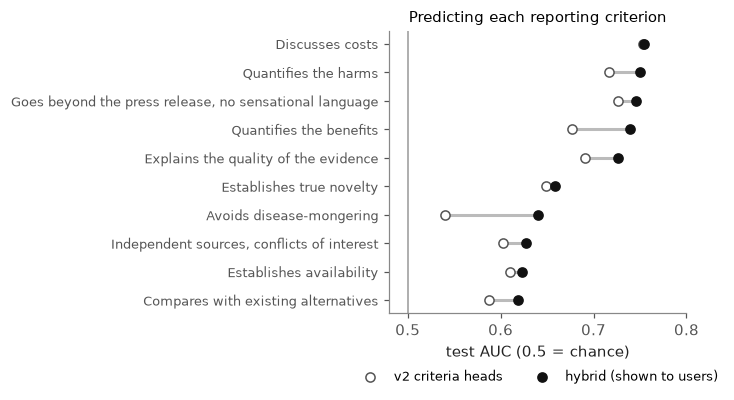

In [16]:
t = pd.DataFrame({"v2 heads": auc["v2"].values, "hybrid": auc["hybrid"].values},
                 index=[CRITERION_NAME[k] for k in CRITERIA]).sort_values("hybrid")
fig, ax = plt.subplots(figsize=(6.6, 3.8))
yy = np.arange(len(t))
ax.hlines(yy, t["v2 heads"], t["hybrid"], color="#bbb", lw=2)
ax.scatter(t["v2 heads"], yy, s=36, facecolor="white", edgecolor="#555", zorder=3, label="v2 criteria heads")
ax.scatter(t["hybrid"], yy, s=36, color="#111", zorder=3, label="hybrid (shown to users)")
ax.axvline(0.5, color="#999", lw=1)
ax.set_yticks(yy, t.index, fontsize=8.5); ax.set_xlim(0.48, 0.8); ax.set_xlabel("test AUC (0.5 = chance)")
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title("Predicting each reporting criterion", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "tier2_v2_criteria_auc.png", dpi=200, bbox_inches="tight"); plt.show()

In [17]:
v = hjs["verdict"]
print("Should the VERDICT also switch to a composer over the hybrid criteria?")
print(pd.DataFrame(v).T[["val_cv_macro_f1", "val_cv_auc", "test_macro_f1", "test_auc"]].to_string())

Should the VERDICT also switch to a composer over the hybrid criteria?
        val_cv_macro_f1  val_cv_auc  test_macro_f1  test_auc
v2               0.6365      0.6392         0.6971    0.7256
hybrid           0.6576      0.6699         0.6675    0.6927


## 7. Where the verdict goes wrong

In [18]:
err = pd.DataFrame({"rating": test.rating, "subset": test.subset, "correct": pred_v2 == y_test,
                    "words": [len(x.split()) for x in X["test"]], "pred_credible": pred_v2, "credible": y_test})
print("Accuracy by the reviewers' star rating (the label boundary is between 2 and 3 stars)")
print(err.groupby("rating").correct.agg(["mean", "size"]).round(3).rename(columns={"mean": "accuracy", "size": "n"}), "\n")
print("Accuracy by source")
print(err.groupby("subset").correct.agg(["mean", "size"]).round(3).rename(columns={"mean": "accuracy", "size": "n"}), "\n")

err["length"] = pd.qcut(err.words, 4, labels=["shortest 25%", "second", "third", "longest 25%"])
g = err.groupby("length", observed=True).agg(n=("correct", "size"), truly_credible=("credible", "mean"),
                                             predicted_credible=("pred_credible", "mean"), accuracy=("correct", "mean"))
print("Does article length drive the verdict?")
print(g.round(3).to_string())
print(f"\nword count alone as a predictor: AUC {roc_auc_score(y_test, err.words):.3f}   "
      f"model: AUC {roc_auc_score(y_test, S_test['credibility']):.3f}")
for q, gg in err.assign(s=S_test["credibility"]).groupby("length", observed=True):
    print(f"  within {q:<13} model AUC {roc_auc_score(gg.credible, gg.s):.3f}   word count AUC {roc_auc_score(gg.credible, gg.words):.3f}")

Accuracy by the reviewers' star rating (the label boundary is between 2 and 3 stars)
        accuracy    n
rating               
0          0.333    3
1          0.613   31
2          0.575   73
3          0.705  105
4          0.879   66
5          0.975   40 

Accuracy by source
               accuracy    n
subset                      
HealthRelease     0.631   84
HealthStory       0.769  234 

Does article length drive the verdict?
               n  truly_credible  predicted_credible  accuracy
length                                                        
shortest 25%  80           0.562               0.550     0.712
second        79           0.658               0.620     0.709
third         79           0.722               0.734     0.709
longest 25%   80           0.712               0.812     0.800

word count alone as a predictor: AUC 0.575   model: AUC 0.726
  within shortest 25%  model AUC 0.770   word count AUC 0.405
  within second        model AUC 0.645   word count AUC 0.

## 8. The router

60 words or fewer goes to Tier 1, longer text to Tier 2.

In [19]:
t1 = pd.concat([pd.read_csv(ROOT / "datasets" / "processed_tier1" / f"{s}.csv") for s in ("train", "validation", "test")])
claims = t1.drop_duplicates("claim").claim
cw = claims.str.split().str.len()
aw = pd.Series([len(t.split()) for t in X["train"] + X["val"] + X["test"]])
r1 = np.array([route(c) == "tier1" for c in claims])
r2 = np.array([route(t) == "tier2" for t in X["train"] + X["val"] + X["test"]])
print(f"router threshold: {ROUTER_MAX_WORDS} words")
print(f"Tier 1 claims   n={len(cw):5d}  words {cw.min()}-{cw.max()} (median {cw.median():.0f})   routed to Tier 1: {r1.sum()}/{len(r1)}")
print(f"Tier 2 articles n={len(aw):5d}  words {aw.min()}-{aw.max()} (median {aw.median():.0f})   routed to Tier 2: {r2.sum()}/{len(r2)}")
print(f"overall: {r1.sum() + r2.sum()} of {len(r1) + len(r2)} texts routed to the right tier")
print("\nthe longest Tier 1 claim:", claims.iloc[int(np.argmax(cw.values))][:300])

router threshold: 60 words
Tier 1 claims   n= 2956  words 3-102 (median 13)   routed to Tier 1: 2948/2956
Tier 2 articles n= 2119  words 64-4296 (median 644)   routed to Tier 2: 2119/2119
overall: 5067 of 5075 texts routed to the right tier

the longest Tier 1 claim: These measures can help to stop the spread of the virus: Cancel events where lots of people gather, like concerts, festivals, and conferences. Work from home. Keep kids out of school. Don't travel by plane or train. Visit with family and friends by phone and computer instead of in person. Stand at l


## 9. Explanations

Sentence level SHAP: each sentence is one feature, removed by deletion. Only the first 512 tokens are explained.

In [20]:
demo = json.load(open(ROOT / "tier2" / "demo_examples.json"))
row = test.set_index("article_id").loc[demo[0]["article_id"]]
t0 = time.time()
res = eng.assess(article_text(row.title, row.text), explain=True)
print(f"{row.title}\n")
print(f"verdict: {DISPLAY[res['verdict']]}   (credibility {res['credibility']:.3f}, threshold {res['threshold']:.3f})")
print(f"reviewers: {row.rating} of 5 stars -> {row.binary_label}")
print(f"the model read {res['words_read']} of {res['n_words']} words; explanation took {time.time()-t0:.1f}s\n")
ex = res["explanation"]
order = np.argsort(ex["credibility"])
print("Sentences that pushed hardest toward 'falls short':")
for j in order[:3]:
    print(f"  {ex['credibility'][j]:+.3f}  {ex['sentences'][j][:150]}")
print("\nSentences that pushed hardest toward 'meets standards':")
for j in order[::-1][:3]:
    print(f"  {ex['credibility'][j]:+.3f}  {ex['sentences'][j][:150]}")

New Asthma Treatment: Pill Makes Huge Difference In Patients With Severe Symptoms

verdict: Falls short of reporting standards   (credibility 0.271, threshold 0.472)
reviewers: 1 of 5 stars -> NOT_CREDIBLE
the model read 388 of 388 words; explanation took 7.6s

Sentences that pushed hardest toward 'falls short':
  -0.099  Ultimately, the researchers hope that the drug “could likewise help to stop preventable asthma attacks, reduce hospital admissions and improve day-to-
  -0.059  “Most treatments might improve some of these features of disease, but with Fevipiprant improvements were seen with all the types of tests.
  -0.047  As the researchers tracked the participants over the course of 12 weeks, they found that those taking the drug saw a decrease in their sputum eosinoph

Sentences that pushed hardest toward 'meets standards':
  +0.029  For people with asthma, a sputum eosinophil reading will typically be around five percent, compared to people without asthma, who have readings that

In [21]:
print("Criteria, model against reviewers:")
for c in res["criteria"]:
    truth = row[f"fail_{c['key']}"]
    truth = "not graded" if pd.isna(truth) else ("not met" if truth == 1 else "met")
    print(f"  {c['name']:<56} model: {'met' if c['met'] else 'NOT MET':<8} (p={c['p_fail']:.2f})  reviewers: {truth}")

for k in ("independent_srcs", "benefits"):
    v = np.asarray(ex["criteria"][k])
    print(f"\nSentences driving '{CRITERION_NAME[k]}' (positive = toward 'not met'):")
    for j in np.argsort(-np.abs(v))[:3]:
        print(f"  {v[j]:+.3f}  {ex['sentences'][j][:150]}")
    print(f"What the reviewer wrote:\n  {' '.join(str(row[f'why_{k}']).split())[:500]}")

Criteria, model against reviewers:
  Discusses costs                                          model: NOT MET  (p=0.89)  reviewers: not met
  Quantifies the benefits                                  model: NOT MET  (p=0.82)  reviewers: not met
  Quantifies the harms                                     model: NOT MET  (p=0.88)  reviewers: not met
  Explains the quality of the evidence                     model: NOT MET  (p=0.74)  reviewers: not met
  Avoids disease-mongering                                 model: met      (p=0.15)  reviewers: met
  Independent sources, conflicts of interest               model: NOT MET  (p=0.81)  reviewers: not met
  Compares with existing alternatives                      model: NOT MET  (p=0.62)  reviewers: not met
  Establishes availability                                 model: NOT MET  (p=0.51)  reviewers: not met
  Establishes true novelty                                 model: NOT MET  (p=0.43)  reviewers: not met
  Goes beyond the press release, 

### Are the explanations faithful, and do they match the reviewers?

A deletion test against random removal, and agreement with the sentences the reviewers quoted.

In [22]:
if not FA.CACHE.exists():
    FA.compute()                        # several seconds per article on a laptop GPU
results = FA.load()
print(f"cached SHAP explanations: {len(results)} of {len(test)} test articles")
print(f"time per article (SHAP + deletion test): median {np.median([r['seconds'] for r in results]):.1f}s")

ag = FA.reviewer_agreement(results, test)
print(f"\n(article, criterion) pairs where the reviewer quoted a sentence the model read: {len(ag)}")
print(f"  top-3 SHAP sentences that the reviewer quoted: {ag.precision_at_k.mean():.3f}   chance: {ag.chance_at_k.mean():.3f}")
print(f"  rank AUC of quoted sentences: {ag.rank_auc.mean():.3f}   (0.5 = chance)")
w = stats.wilcoxon(ag.precision_at_k - ag.chance_at_k, alternative="greater")
tt = stats.ttest_1samp(ag.rank_auc, 0.5, alternative="greater")
print(f"  Wilcoxon, precision > chance: p = {w.pvalue:.1e}      t-test, rank AUC > 0.5: p = {tt.pvalue:.1e}")
print(f"  pairs where SHAP beats chance: {(ag.precision_at_k > ag.chance_at_k).mean():.1%}")

per = ag.groupby("criterion").agg(pairs=("rank_auc", "size"), precision_at_3=("precision_at_k", "mean"),
                                  chance=("chance_at_k", "mean"), rank_auc=("rank_auc", "mean")).round(3)
per.insert(0, "name", per.index.map(CRITERION_NAME))
print("\n", per.sort_values("pairs", ascending=False).to_string())

va = FA.verdict_agreement(results, test)
print(f"\nverdict level ({len(va)} articles; rationale = every read sentence quoted under any criterion):")
print(f"  top-3 by |SHAP| quoted: {va.precision_at_k.mean():.3f}   chance {va.chance_at_k.mean():.3f}   "
      f"rank AUC {va.rank_auc.mean():.3f}   t-test p = {stats.ttest_1samp(va.rank_auc, 0.5, alternative='greater').pvalue:.2f}")

cached SHAP explanations: 318 of 318 test articles
time per article (SHAP + deletion test): median 5.5s



(article, criterion) pairs where the reviewer quoted a sentence the model read: 355
  top-3 SHAP sentences that the reviewer quoted: 0.130   chance: 0.095
  rank AUC of quoted sentences: 0.548   (0.5 = chance)
  Wilcoxon, precision > chance: p = 1.3e-01      t-test, rank AUC > 0.5: p = 1.2e-03
  pairs where SHAP beats chance: 33.5%

                                                                     name  pairs  precision_at_3  chance  rank_auc
criterion                                                                                                        
benefits                                         Quantifies the benefits    105           0.168   0.103     0.595
evidence_quality                    Explains the quality of the evidence     65           0.118   0.102     0.494
novelty                                         Establishes true novelty     57           0.088   0.102     0.532
alternatives                         Compares with existing alternatives     31           0.0


verdict level (186 articles; rationale = every read sentence quoted under any criterion):
  top-3 by |SHAP| quoted: 0.186   chance 0.182   rank AUC 0.502   t-test p = 0.44


In [23]:
# Are the per-criterion explanations different from each other? Compared with the
# earlier run that explained the v2 criteria heads (same articles).
old = {r["article_id"]: r for r in (json.loads(l) for l in open(OUTP / "tier2_explanations_v2criteria_partial.jsonl"))}
def redundancy(r):
    M = np.array([r["criteria"][k] for k in CRITERIA]); c = np.corrcoef(M)
    return c[~np.eye(len(c), dtype=bool)].mean()
shared = [r for r in results if r["article_id"] in old]
print(f"{len(shared)} articles explained under both criteria models")
print(f"  mean correlation between the ten criteria explanations: v2 heads {np.mean([redundancy(old[r['article_id']]) for r in shared]):.3f}"
      f"   hybrid {np.mean([redundancy(r) for r in shared]):.3f}")
ag_old = FA.reviewer_agreement(list(old.values()), test)
ag_new = ag[ag.article_id.isin(old)]
print(f"  agreement with reviewers' quotes (rank AUC): v2 heads {ag_old.rank_auc.mean():.3f} (n={len(ag_old)})"
      f"   hybrid {ag_new.rank_auc.mean():.3f} (n={len(ag_new)})")

140 articles explained under both criteria models
  mean correlation between the ten criteria explanations: v2 heads 0.771   hybrid 0.438
  agreement with reviewers' quotes (rank AUC): v2 heads 0.487 (n=152)   hybrid 0.520 (n=152)


Deletion test on 311 articles (3 of about 18 read sentences removed)

  remove the 3 sentences SHAP blames for 'falls short'  -> credibility +0.0307
  remove the 3 sentences SHAP credits for 'meets'       -> credibility -0.0265
  remove 3 random sentences (mean of 10 draws)          -> credibility -0.0015   (mean absolute change 0.0266)

  'falls short' removal raises the score more than random on 76.8% of articles
  'meets' removal lowers the score more than random on   73.0% of articles
  Wilcoxon p: 3.0e-24 and 2.8e-20


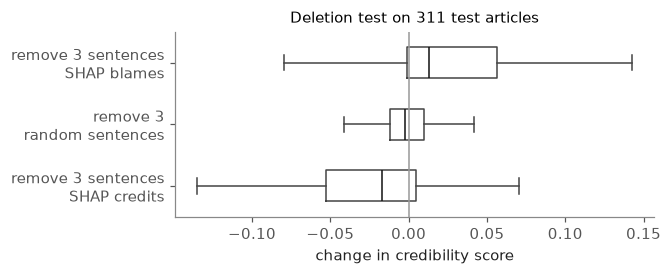

In [24]:
dl = FA.deletion_table(results)
print(f"Deletion test on {len(dl)} articles (3 of about 18 read sentences removed)\n")
print(f"  remove the 3 sentences SHAP blames for 'falls short'  -> credibility {dl.drop_neg.mean():+.4f}")
print(f"  remove the 3 sentences SHAP credits for 'meets'       -> credibility {dl.drop_pos.mean():+.4f}")
print(f"  remove 3 random sentences (mean of 10 draws)          -> credibility {dl.random_mean.mean():+.4f}"
      f"   (mean absolute change {dl.random_abs_mean.mean():.4f})\n")
print(f"  'falls short' removal raises the score more than random on {(dl.drop_neg > dl.random_mean).mean():.1%} of articles")
print(f"  'meets' removal lowers the score more than random on   {(dl.drop_pos < dl.random_mean).mean():.1%} of articles")
print(f"  Wilcoxon p: {stats.wilcoxon(dl.drop_neg - dl.random_mean, alternative='greater').pvalue:.1e} and "
      f"{stats.wilcoxon(dl.drop_pos - dl.random_mean, alternative='less').pvalue:.1e}")

fig, ax = plt.subplots(figsize=(6.2, 2.6))
parts = [dl.drop_pos, dl.random_mean, dl.drop_neg]
names = ["remove 3 sentences\nSHAP credits", "remove 3\nrandom sentences", "remove 3 sentences\nSHAP blames"]
ax.boxplot(parts, vert=False, widths=0.5, showfliers=False,
           medianprops={"color": "#111"}, boxprops={"color": "#444"}, whiskerprops={"color": "#444"},
           capprops={"color": "#444"})
ax.set_yticks([1, 2, 3], names); ax.axvline(0, color="#999", lw=1)
ax.set_xlabel("change in credibility score")
ax.set_title(f"Deletion test on {len(dl)} test articles", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "tier2_v2_deletion_test.png", dpi=200, bbox_inches="tight"); plt.show()

## 10. The demonstration articles

The four articles shown in the web app, all from the test set.

In [25]:
te_idx = test.set_index("article_id")
rows = []
for e in demo:
    r = te_idx.loc[e["article_id"]]
    out = eng.assess(article_text(r.title, r.text))
    rows.append({"example": e["label"][:60], "reviewers": f"{r.rating}/5 {r.binary_label}",
                 "model": out["verdict"], "score": round(out["credibility"], 3),
                 "criteria not met": ", ".join(c["key"] for c in out["criteria"] if not c["met"])})
print(pd.DataFrame(rows).to_string(index=False))

                                                     example        reviewers        model  score                                                                                               criteria not met
   Poorly reported - New asthma pill 'makes huge difference' 1/5 NOT_CREDIBLE NOT_CREDIBLE  0.271 costs, benefits, harms, evidence_quality, independent_srcs, alternatives, availability, novelty, press_release
          Poorly reported - Egg producers fund study on eggs 1/5 NOT_CREDIBLE NOT_CREDIBLE  0.355 costs, benefits, harms, evidence_quality, independent_srcs, alternatives, availability, novelty, press_release
 Well reported - Zinc will help your cold, at least a little     4/5 CREDIBLE     CREDIBLE  0.680                                                                                                               
Model disagrees with the reviewers - Tai chi and fibromyalgi     4/5 CREDIBLE NOT_CREDIBLE  0.307 costs, benefits, harms, evidence_quality, independent_srcs, altern

In [26]:
summary = {
    "task": "Tier 2 v2 - article reporting quality (FakeHealth / HealthNewsReview)",
    "verdict_model": "5-member PubMedBERT ensemble (ordinal CORAL + 10 criteria heads); verdict = composer over the ensemble's criteria (crit_lr)",
    "criteria_model": "per-criterion blend of the ensemble's criteria probabilities and TF-IDF logistic regression",
    "test": {k: round(float(v), 4) for k, v in m_v2.items()},
    "baselines_test": table.drop(index="v2 ensemble (shipped)").round(4).to_dict("index"),
    "paired_bootstrap": boot.round(4).to_dict("index"),
    "retraining_test": {"n_seeds": int(len(a)), "v1_mean": round(float(a.mean()), 4),
                        "v2_mean": round(float(b.mean()), 4), "v2_std": round(float(b.std(ddof=1)), 4),
                        "welch_p": round(float(p), 4)},
    "criteria": {"v1": summ.loc["v1 criteria model"].round(4).to_dict(),
                 "v2_heads": summ.loc["v2 criteria heads"].round(4).to_dict(),
                 "hybrid": summ.loc["hybrid (shown)"].round(4).to_dict(),
                 "hybrid_minus_v2_mean_auc": bb,
                 "decision_accuracy": {k: round(float(collapse.loc[k, "decision accuracy"]), 4) for k in
                                       ("each criterion's usual outcome (constant)", "v2 criteria heads", "hybrid (shown)")}},
    "router": {"correct": int(r1.sum() + r2.sum()), "total": int(len(r1) + len(r2))},
    "explanations": {"articles": len(results), "reviewer_pairs": int(len(ag)),
                     "precision_at_3": round(float(ag.precision_at_k.mean()), 4),
                     "chance_at_3": round(float(ag.chance_at_k.mean()), 4),
                     "rank_auc": round(float(ag.rank_auc.mean()), 4),
                     "verdict_level_rank_auc": round(float(va.rank_auc.mean()), 4),
                     "deletion_drop_neg": round(float(dl.drop_neg.mean()), 4),
                     "deletion_drop_pos": round(float(dl.drop_pos.mean()), 4),
                     "deletion_random": round(float(dl.random_mean.mean()), 4),
                     "deletion_neg_beats_random": round(float((dl.drop_neg > dl.random_mean).mean()), 4),
                     "deletion_pos_beats_random": round(float((dl.drop_pos < dl.random_mean).mean()), 4)},
}
json.dump(summary, open(OUTP / "tier2_v2_final_metrics.json", "w"), indent=2, default=float)
print("wrote outputs/tier2_v2_final_metrics.json")

wrote outputs/tier2_v2_final_metrics.json
